In [1]:
# Llama-3.2 is gated. Store a Kaggle secret named HF_TOKEN.
from kaggle_secrets import UserSecretsClient
from huggingface_hub import login

try:
    token = UserSecretsClient().get_secret('HF_TOKEN')
    login(token=token)
    print('Hugging Face login: OK')
except Exception as exc:
    print('HF login was not completed automatically:', exc)
    print('If the model is already cached and accessible, you can continue.')


Hugging Face login: OK


In [2]:
import torch
from transformers import AutoModelForCausalLM
import matplotlib.pyplot as plt

model = AutoModelForCausalLM.from_pretrained('meta-llama/Llama-3.2-1B',)

config.json:   0%|          | 0.00/843 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.47GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/185 [00:00<?, ?B/s]

In [3]:
# TODO for Question 4
"""

Hint:
# Analyze the weights of the query projection layer (q_proj) where layer = k
 q_weight = model.model.layers[k].self_attn.q_proj.weight.detach()

# Apply SVD to decompose the weight matrix into U (left singular vectors), S (singular values), and V (right singular vectors).
 U, S, Vh = torch.linalg.svd(q_weight.float(), full_matrices=False)

# Compute the retained energy ratio (Cumulative energy) of each singular value.
energy_ratios = torch.cumsum(S ** 2, dim=0) / torch.sum(S ** 2) * 100
"""


'\n\nHint:\n# Analyze the weights of the query projection layer (q_proj) where layer = k\n q_weight = model.model.layers[k].self_attn.q_proj.weight.detach()\n\n# Apply SVD to decompose the weight matrix into U (left singular vectors), S (singular values), and V (right singular vectors).\n U, S, Vh = torch.linalg.svd(q_weight.float(), full_matrices=False)\n\n# Compute the retained energy ratio (Cumulative energy) of each singular value.\nenergy_ratios = torch.cumsum(S ** 2, dim=0) / torch.sum(S ** 2) * 100\n'

Layer 0: min rank = 62, energy = 50.17%


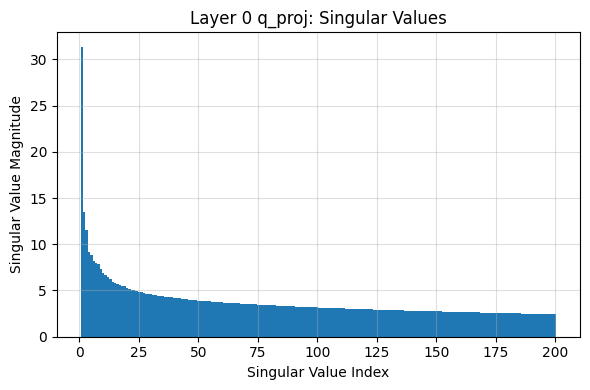

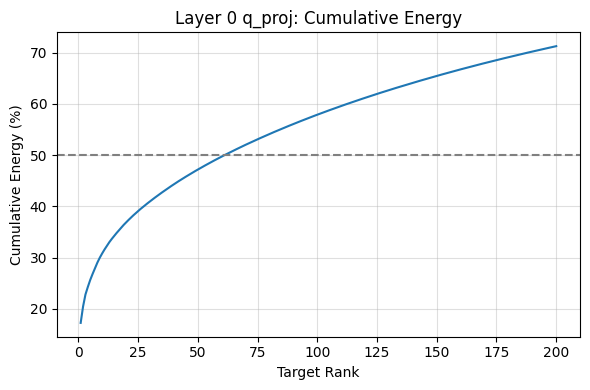

Layer 7: min rank = 120, energy = 50.20%


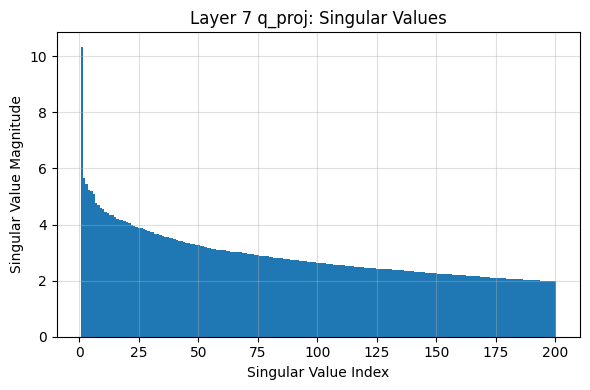

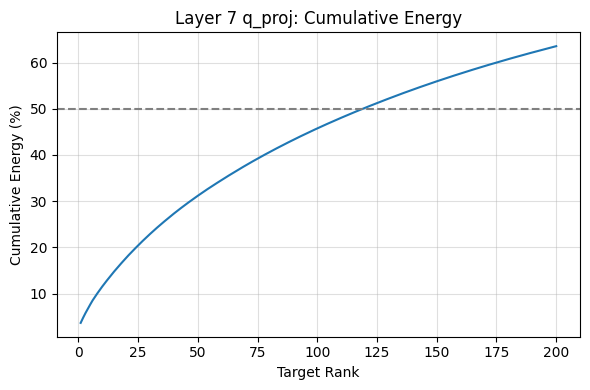

Layer 15: min rank = 84, energy = 50.12%


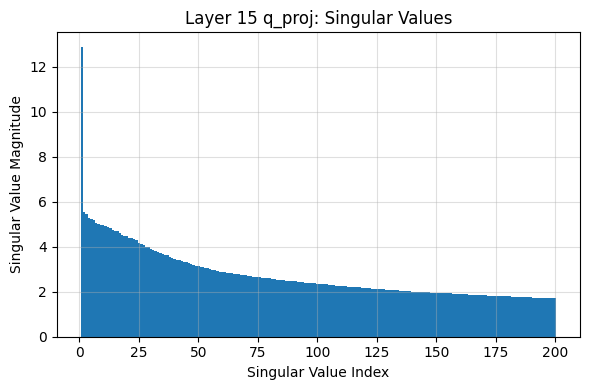

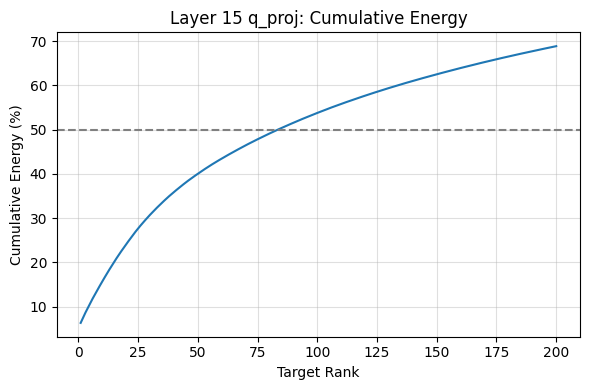

Summary: {0: 62, 7: 120, 15: 84}


In [4]:
min_ranks = {} # 記錄每層答案

for k in [0, 7, 15]:
    # 1. 取權重，做 SVD
    q_weight = model.model.layers[k].self_attn.q_proj.weight.detach() # 取出模型的的k層transformer (k=0~15)，取得這一層的注意力機制（Self-Attention）中的 query 投影矩陣，只拿數值，不追蹤梯度
    U, S, Vh = torch.linalg.svd(q_weight.float(), full_matrices = False) # 把矩陣分解成 U, S, V， S 就是由大到小排好的奇異值

    # 2. 累積能量與最小 rank
    energy_ratios = torch.cumsum(S**2, dim=0)/torch.sum(S**2)*100
    min_rank = int((energy_ratios>=50).nonzero()[0])+1 # 每個位置是否已達 50%，得到一串 True/False，第一個 True 出現的位置編號，位置從 0 開始算，rank 從 1 開始算，所以要 +1
    min_ranks[k] = min_rank
    print(f'Layer {k}: min rank = {min_rank}, energy = {energy_ratios[min_rank-1]:.2f}%')
    
    x = range(1, 201)   # x 軸：第 1 到第 200 個

    # 圖 1：奇異值大小（長條圖）
    plt.figure(figsize=(6, 4))
    plt.bar(x, S[:200], width=1.0)
    plt.xlabel('Singular Value Index')
    plt.ylabel('Singular Value Magnitude')
    plt.title(f'Layer {k} q_proj: Singular Values')
    plt.grid(True, alpha=0.4)
    plt.tight_layout()
    plt.savefig(f'layer{k}_singular_values.png', dpi=200)
    plt.show()

    # 圖 2：累積能量（折線圖）
    plt.figure(figsize=(6, 4))
    plt.plot(x, energy_ratios[:200])
    plt.axhline(50, linestyle='--', color='gray')   # 50% 參考線
    plt.xlabel('Target Rank')
    plt.ylabel('Cumulative Energy (%)')
    plt.title(f'Layer {k} q_proj: Cumulative Energy')
    plt.grid(True, alpha=0.4)
    plt.tight_layout()
    plt.savefig(f'layer{k}_cumulative_energy.png', dpi=200)
    plt.show()
    
print('Summary:', min_ranks)

In [5]:
print('Layer | sigma1 | sigma16 | energy@r=1 | energy@r=16 | energy@r=64 | energy@r=256 | min rank (50%)')
for k in [0, 7, 15]:
    q_weight = model.model.layers[k].self_attn.q_proj.weight.detach()
    S = torch.linalg.svdvals(q_weight.float())
    energy_ratios = torch.cumsum(S ** 2, dim=0) / torch.sum(S ** 2) * 100
    min_rank = int((energy_ratios >= 50).nonzero()[0]) + 1
    print(f'{k:5d} | {S[0]:6.2f} | {S[15]:7.2f} | {energy_ratios[0]:9.2f}% | '
          f'{energy_ratios[15]:10.2f}% | {energy_ratios[63]:10.2f}% | {energy_ratios[255]:11.2f}% | {min_rank}')

Layer | sigma1 | sigma16 | energy@r=1 | energy@r=16 | energy@r=64 | energy@r=256 | min rank (50%)
    0 |  31.36 |    5.68 |     17.24% |      34.77% |      50.64% |       76.35% | 62
    7 |  10.34 |    4.21 |      3.66% |      15.39% |      35.87% |       70.14% | 120
   15 |  12.88 |    4.68 |      6.36% |      20.95% |      44.69% |       74.31% | 84


In [6]:
for k in [0, 7, 15]:
    S = torch.linalg.svdvals(model.model.layers[k].self_attn.q_proj.weight.detach().float())
    E = S ** 2 / torch.sum(S ** 2) * 100     # 每個奇異值佔的能量 %
    n, r = len(S), 16
    starts = {'Top': 0, '25%': n // 4, '50%': n // 2, 'Bottom': n - r}
    print(f'Layer {k}: ' + ', '.join(f'{name} = {E[s:s+r].sum():.3f}%' for name, s in starts.items()))

Layer 0: Top = 34.767%, 25% = 0.515%, 50% = 0.105%, Bottom = 0.000%
Layer 7: Top = 15.386%, 25% = 0.654%, 50% = 0.128%, Bottom = 0.000%
Layer 15: Top = 20.954%, 25% = 0.565%, 50% = 0.116%, Bottom = 0.000%
